# Practical 8 - Noise Generation

Aim: Generate uniform, Gaussian, Erlang, exponential and Rayleigh noise from PDF equations and compare with built-in functions using histograms.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

np.random.seed(10)
n = 20000

Name: Navjot Singh
Roll No: 2025010071


In [2]:
# manual noise using inverse formulas
u = np.random.rand(n)
u1 = np.clip(np.random.rand(n), 1e-12, 1)
u2 = np.random.rand(n)

manual = {}
manual["Uniform"] = -30 + 60 * u
manual["Gaussian"] = 20 * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
manual["Erlang"] = -5 * np.log(np.random.rand(n, 3)).sum(axis=1)
manual["Exponential"] = -10 * np.log(np.clip(u, 1e-12, 1))
manual["Rayleigh"] = 10 * np.sqrt(-2 * np.log(np.clip(u, 1e-12, 1)))

# built-in numpy functions for comparison
builtin = {}
builtin["Uniform"] = np.random.uniform(-30, 30, n)
builtin["Gaussian"] = np.random.normal(0, 20, n)
builtin["Erlang"] = np.random.gamma(3, 5, n)
builtin["Exponential"] = np.random.exponential(10, n)
builtin["Rayleigh"] = np.random.rayleigh(10, n)

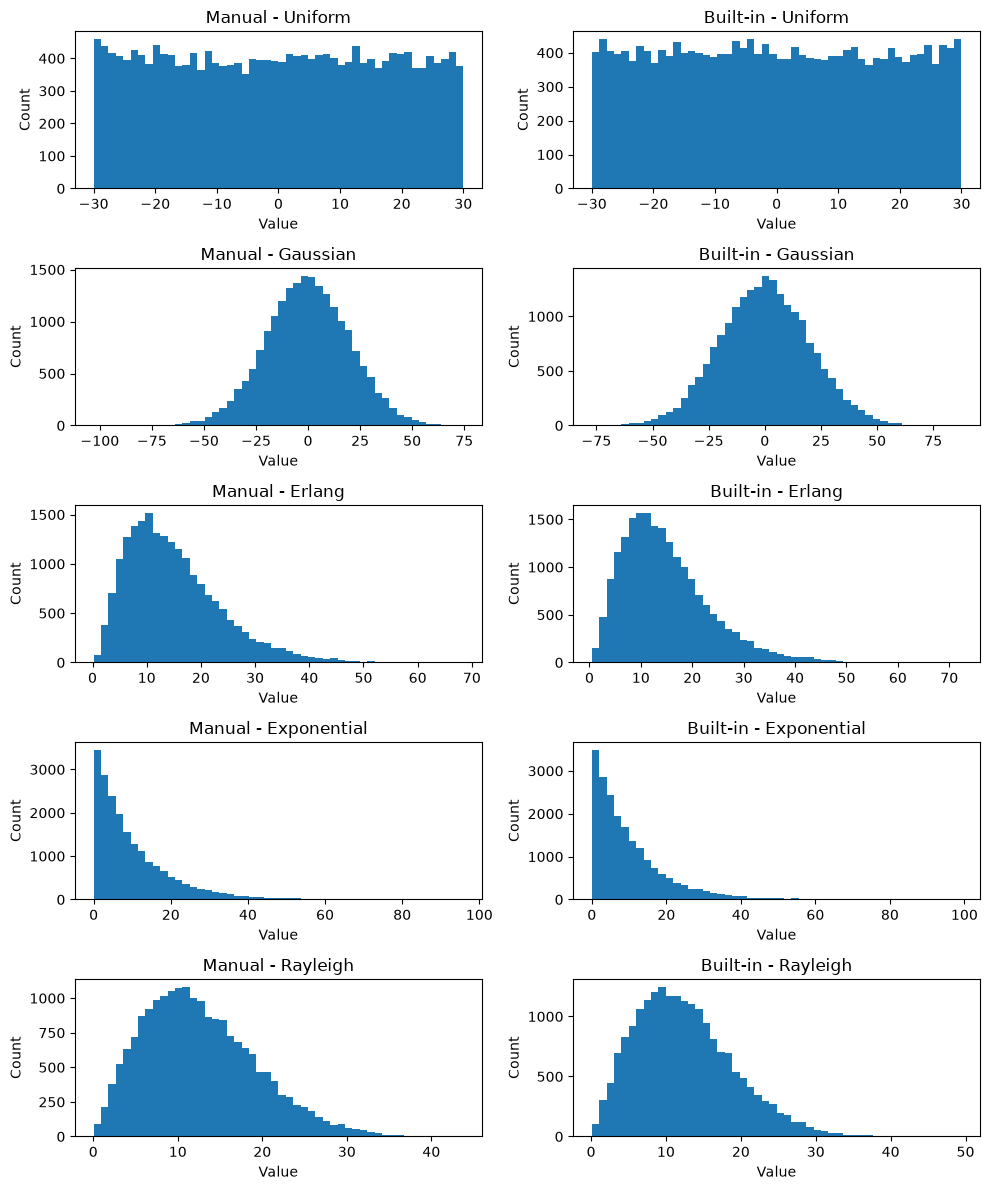

In [3]:
# compare the histograms
names = ["Uniform", "Gaussian", "Erlang", "Exponential", "Rayleigh"]

plt.figure(figsize=(10, 12))
for i in range(5):
    name = names[i]

    plt.subplot(5, 2, 2 * i + 1)
    plt.hist(manual[name], bins=50)
    plt.title("Manual - " + name)
    plt.xlabel("Value")
    plt.ylabel("Count")

    plt.subplot(5, 2, 2 * i + 2)
    plt.hist(builtin[name], bins=50)
    plt.title("Built-in - " + name)
    plt.xlabel("Value")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()